In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

## 1. Load Dataset and Prepare Training Matrix

In [2]:
DATASET_PATH = "../datasets/food_table_clean.csv"
df_raw = pd.read_csv(DATASET_PATH)
print(f"Total unique foods in DFTQC dataset: {len(df_raw)}")
df_raw[['food_id', 'food_name', 'category', 'calories', 'sodium_mg', 'sugar_g']].head()

Total unique foods in DFTQC dataset: 224


,food_id,food_name,category,calories,sodium_mg,sugar_g
0,A01,Amaranth Seed,Cereals,375.0,5,1.0
1,A02,Barley,Cereals,336.0,5,1.0
2,A03,Buckwheat Whole,Cereals,323.0,5,1.0
3,A04,Bajra,Cereals,361.0,5,1.0
4,A05,Bamboo Seed,Cereals,367.0,5,1.0


## 2. Generate Medical Condition Pairs & Labels

In [3]:
SODIUM_THRESHOLD_MG = 400.0  # WHO proxy for Hypertension
SUGAR_THRESHOLD_G = 15.0     # ADA proxy for Diabetes

records = []
for _, food in df_raw.iterrows():
    for condition in ["Hypertension", "Diabetes"]:
        label = 1
        if condition == "Hypertension" and float(food.get("sodium_mg", 0) or 0) > SODIUM_THRESHOLD_MG:
            label = 0
        if condition == "Diabetes" and float(food.get("sugar_g", 0) or 0) > SUGAR_THRESHOLD_G:
            label = 0
        records.append({
            "food_id": food["food_id"],
            "food_name": food["food_name"],
            "sodium_mg": float(food.get("sodium_mg", 0) or 0),
            "sugar_g": float(food.get("sugar_g", 0) or 0),
            "carbs_g": float(food.get("carbs_g", 0) or 0),
            "fat_g": float(food.get("fat_g", 0) or 0),
            "calories": float(food.get("calories", 0) or 0),
            "condition": condition,
            "suitable": label
        })

df_ml = pd.DataFrame(records)
ohe = pd.get_dummies(df_ml["condition"], prefix="condition")
for col in ["condition_Diabetes", "condition_Hypertension"]:
    if col not in ohe.columns:
        ohe[col] = False
df_ml = pd.concat([df_ml, ohe], axis=1)

feature_cols = ["sodium_mg", "sugar_g", "carbs_g", "fat_g", "calories", "condition_Diabetes", "condition_Hypertension"]
X = df_ml[feature_cols]
y = df_ml["suitable"]

print(f"Total training records: {len(df_ml)}")
print(f"Class Distribution: Suitable={sum(y==1)}, Unsuitable={sum(y==0)}")

Total training records: 448
Class Distribution: Suitable=421, Unsuitable=27


## 3. Train Decision Tree & Evaluate on Test Set

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

clf = DecisionTreeClassifier(max_depth=4, criterion="gini", random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print(f"Test Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Unsuitable (0)", "Suitable (1)"]))

Test Accuracy: 100.00%

Classification Report:
                precision    recall  f1-score   support

Unsuitable (0)       1.00      1.00      1.00         5
  Suitable (1)       1.00      1.00      1.00        85

      accuracy                           1.00        90
     macro avg       1.00      1.00      1.00        90
  weighted avg       1.00      1.00      1.00        90



## 4. Confusion Matrix Visualization

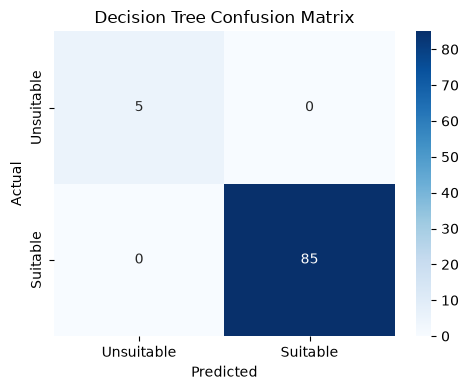

In [5]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Unsuitable", "Suitable"], yticklabels=["Unsuitable", "Suitable"])
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 5. Tree Structure Visualization (White-Box Explainability)

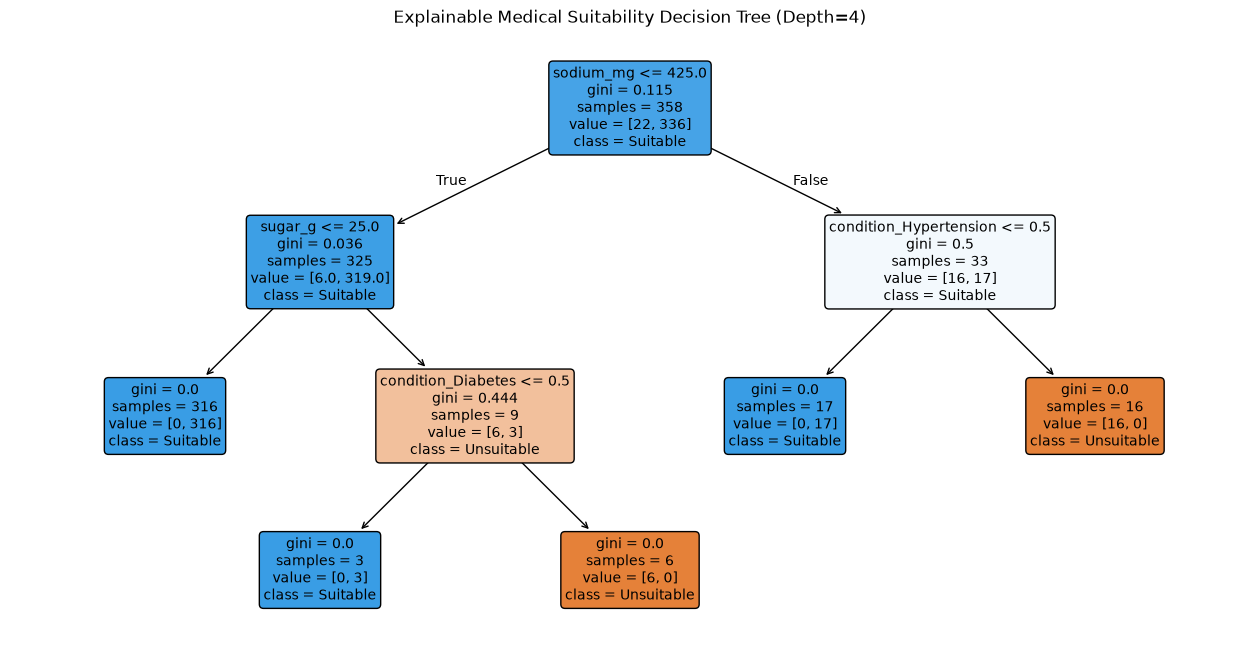

In [6]:
plt.figure(figsize=(16, 8))
plot_tree(clf, feature_names=feature_cols, class_names=["Unsuitable", "Suitable"], filled=True, rounded=True, fontsize=10)
plt.title("Explainable Medical Suitability Decision Tree (Depth=4)")
plt.show()